# Hyperparameter tuning for Random Forest (4 methods) — side-by-side

This notebook demonstrates **four** common hyperparameter tuning approaches on a **non-toy, real dataset**:

**Dataset:** *Breast Cancer Wisconsin (Diagnostic)* (built into scikit-learn)
- **569** samples of fine-needle aspirate cell measurements
- **30** real-valued features (e.g., radius, texture, perimeter)
- Binary target: **malignant vs benign**
- Task: **binary classification**

We compare:
1. **GridSearchCV** (exhaustive search on a small grid)
2. **RandomizedSearchCV** (random sampling with a fixed budget)
3. **HalvingRandomSearchCV** (Successive Halving: more efficient resource allocation)
4. **Optuna (TPE)** (adaptive / Bayesian-style search)

For each method we record:
- best cross-validated score
- test-set score (held-out)
- wall-clock fit/tuning time

Setup your ml environment with:

```
conda create --name ml python=3.11   # You should have this already
conda activate ml
conda install pandas                 # You should have this already
conda install scikit-learn           # You should have this already
conda install matplotlib             # You should have this already

conda install xgboost                  
conda install -c conda-forge optuna scikit-learn
```

In [16]:
import numpy as np
import pandas as pd
from time import perf_counter

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

## 1) Load data and create train/test split

We keep the **test set untouched** until the very end.
All tuning (CV) happens on the **training split** only.

In [17]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target  # 0=malignant, 1=benign in this dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Dataset:", data.DESCR.splitlines()[0])
print("X shape:", X.shape)
print("y positive rate:", float(y.mean()))
print("Train:", X_train.shape, "Test:", X_test.shape)

Dataset: .. _breast_cancer_dataset:
X shape: (569, 30)
y positive rate: 0.6274165202108963
Train: (455, 30) Test: (114, 30)


## 2) Common setup

- We tune a **RandomForestClassifier**.
- Scoring: **F1** (works well for imbalanced-ish binary tasks).
- CV: **5-fold stratified**.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

base_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1,
)

pipe = Pipeline([
    ("rf", base_rf),
])

SCORING = "accuracy"

## 3) Helper: fit a tuned model and benchmark on the test set

In [19]:
def evaluate_on_test(estimator, X_train, y_train, X_test, y_test):
    estimator.fit(X_train, y_train)
    y_pred = estimator.predict(X_test)
    return {
        "test_f1": f1_score(y_test, y_pred),
        "test_accuracy": accuracy_score(y_test, y_pred),
    }

## 4) Method A — GridSearchCV

**Idea:** try **all combinations** in a (small) grid.

**Pros:** systematic, reproducible  
**Cons:** quickly becomes infeasible as the grid grows

In [20]:
from sklearn.model_selection import GridSearchCV

grid_params = {
    "rf__n_estimators": [200, 500],
    "rf__max_depth": [None, 8, 16],
    "rf__min_samples_split": [2, 10],
    "rf__min_samples_leaf": [1, 5],
    "rf__max_features": ["sqrt", 0.5],
}

grid = GridSearchCV(
    estimator=pipe,
    param_grid=grid_params,
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    verbose=0,
    refit=True,
)

t0 = perf_counter()
grid.fit(X_train, y_train)
t_grid = perf_counter() - t0

grid_best_cv = grid.best_score_
grid_best_params = grid.best_params_

grid_test = evaluate_on_test(grid.best_estimator_, X_train, y_train, X_test, y_test)

(grid_best_cv, grid_best_params, t_grid, grid_test)

(0.9626373626373628,
 {'rf__max_depth': None,
  'rf__max_features': 'sqrt',
  'rf__min_samples_leaf': 1,
  'rf__min_samples_split': 2,
  'rf__n_estimators': 200},
 75.44885250000516,
 {'test_f1': 0.9655172413793104, 'test_accuracy': 0.956140350877193})

## 5) Method B — RandomizedSearchCV

**Idea:** sample hyperparameter combinations randomly from a **larger space**.

**Pros:** good results with a fixed budget (`n_iter`), scales better  
**Cons:** not adaptive; may miss narrow “sweet spots” unless budget is big

In [21]:
from sklearn.model_selection import RandomizedSearchCV

rand_params = {
    "rf__n_estimators": np.arange(200, 1200, 100),
    "rf__max_depth": [None] + list(np.arange(4, 33, 4)),
    "rf__min_samples_split": np.arange(2, 51, 2),
    "rf__min_samples_leaf": np.arange(1, 21, 2),
    "rf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.8],
    "rf__bootstrap": [True, False],
}

rand = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=rand_params,
    n_iter=30,                 # fixed compute budget
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=0,
    refit=True,
)

t0 = perf_counter()
rand.fit(X_train, y_train)
t_rand = perf_counter() - t0

rand_best_cv = rand.best_score_
rand_best_params = rand.best_params_

rand_test = evaluate_on_test(rand.best_estimator_, X_train, y_train, X_test, y_test)

(rand_best_cv, rand_best_params, t_rand, rand_test)

(0.956043956043956,
 {'rf__n_estimators': 1000,
  'rf__min_samples_split': 4,
  'rf__min_samples_leaf': 3,
  'rf__max_features': 0.8,
  'rf__max_depth': 32,
  'rf__bootstrap': True},
 97.98333300001104,
 {'test_f1': 0.9583333333333334, 'test_accuracy': 0.9473684210526315})

## 6) Method C — HalvingRandomSearchCV (Successive Halving)

**Idea:** start with many candidates trained with **small resources**, keep the best, then increase resources.

In scikit-learn this is implemented as **HalvingRandomSearchCV**.
For Random Forest, we use `n_estimators` as the **resource** (more trees = more compute).

In [22]:
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingRandomSearchCV

# Important for successive halving with n_estimators:
# warm_start=True allows increasing n_estimators progressively.
rf_halving = RandomForestClassifier(
    random_state=42,
    n_jobs=-1,
    warm_start=True,
)

pipe_halving = Pipeline([
    ("rf", rf_halving),
])

halving_params = {
    "rf__max_depth": [None] + list(np.arange(4, 33, 4)),
    "rf__min_samples_split": np.arange(2, 51, 2),
    "rf__min_samples_leaf": np.arange(1, 21, 2),
    "rf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.8],
    "rf__bootstrap": [True, False],
}

halving = HalvingRandomSearchCV(
    estimator=pipe_halving,
    param_distributions=halving_params,
    factor=3,                         # keep ~1/3 each round
    resource="rf__n_estimators",
    min_resources=50,                 # start with 50 trees
    max_resources=500,                # end with 500 trees
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=0,
    refit=True,
)

t0 = perf_counter()
halving.fit(X_train, y_train)
t_halving = perf_counter() - t0

halving_best_cv = halving.best_score_
halving_best_params = halving.best_params_

halving_test = evaluate_on_test(halving.best_estimator_, X_train, y_train, X_test, y_test)

(halving_best_cv, halving_best_params, t_halving, halving_test)

c:\Users\petra\anaconda3\envs\ml\lib\site-packages\sklearn\ensemble\_forest.py:435: UserWarning: Warm-start fitting without increasing n_estimators does not fit new trees.
  warn(


(0.9538461538461538,
 {'rf__min_samples_split': 2,
  'rf__min_samples_leaf': 9,
  'rf__max_features': 0.3,
  'rf__max_depth': 16,
  'rf__bootstrap': False,
  'rf__n_estimators': 450},
 9.834391600015806,
 {'test_f1': 0.9655172413793104, 'test_accuracy': 0.956140350877193})

## 7) Method D — Optuna (adaptive search)

Optuna is **not part of scikit-learn**, but it is compatible with scikit-learn estimators.
It proposes new trials based on previous results (commonly via **TPE**).

If `optuna` is not installed, install it (e.g., conda-forge):
```bash
conda install -c conda-forge optuna
```

In [23]:
try:
    import optuna
    from optuna.samplers import TPESampler
except Exception as e:
    optuna = None
    print("Optuna import failed:", e)

Optuna import failed: No module named 'optuna'


In [24]:
def optuna_search_rf(X_train, y_train, n_trials=25, seed=42):
    if optuna is None:
        raise ImportError("Optuna not installed. Run: conda install -c conda-forge optuna")

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
            "max_depth": trial.suggest_categorical("max_depth", [None] + list(range(4, 33, 4))),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 50, step=2),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20, step=2),
            "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.3, 0.5, 0.8]),
            "bootstrap": trial.suggest_categorical("bootstrap", [True, False]),
        }

        model = RandomForestClassifier(
            random_state=42,
            n_jobs=-1,
            **params
        )
        # Cross-validated score on training data
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
        return float(scores.mean())

    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
    t0 = perf_counter()
    study.optimize(objective, n_trials=n_trials)
    t_opt = perf_counter() - t0

    best_params = study.best_params
    best_cv = study.best_value

    best_model = RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        **best_params
    )
    test_metrics = evaluate_on_test(best_model, X_train, y_train, X_test, y_test)

    return best_cv, best_params, t_opt, test_metrics

if optuna is not None:
    opt_best_cv, opt_best_params, t_opt, opt_test = optuna_search_rf(X_train, y_train, n_trials=25, seed=42)
    (opt_best_cv, opt_best_params, t_opt, opt_test)
else:
    "Install optuna to run this section."

## 8) Side-by-side comparison (scores + timing)

In [25]:
rows = [
    {
        "method": "GridSearchCV",
        "cv_f1": grid_best_cv,
        "test_f1": grid_test["test_f1"],
        "test_accuracy": grid_test["test_accuracy"],
        "time_sec": t_grid,
        "best_params": grid_best_params,
        "description": "Exhaustive search over a small grid (systematic but can explode).",
    },
    {
        "method": "RandomizedSearchCV",
        "cv_f1": rand_best_cv,
        "test_f1": rand_test["test_f1"],
        "test_accuracy": rand_test["test_accuracy"],
        "time_sec": t_rand,
        "best_params": rand_best_params,
        "description": "Random sampling from a larger space with fixed budget (n_iter).",
    },
    {
        "method": "HalvingRandomSearchCV",
        "cv_f1": halving_best_cv,
        "test_f1": halving_test["test_f1"],
        "test_accuracy": halving_test["test_accuracy"],
        "time_sec": t_halving,
        "best_params": halving_best_params,
        "description": "Successive halving: allocate more resources only to promising candidates.",
    },
]

if optuna is not None:
    rows.append({
        "method": "Optuna (TPE)",
        "cv_f1": opt_best_cv,
        "test_f1": opt_test["test_f1"],
        "test_accuracy": opt_test["test_accuracy"],
        "time_sec": t_opt,
        "best_params": opt_best_params,
        "description": "Adaptive search that proposes trials using previous results (Bayesian-style).",
    })

results = pd.DataFrame(rows).sort_values("cv_f1", ascending=False)
results[["method","cv_f1","test_f1","test_accuracy","time_sec","description"]]

,method,cv_f1,test_f1,test_accuracy,time_sec,description
0,GridSearchCV,0.962637,0.965517,0.956140,75.448853,Exhaustive search over a small grid (systemati...
1,RandomizedSearchCV,0.956044,0.958333,0.947368,97.983333,Random sampling from a larger space with fixed...
2,HalvingRandomSearchCV,0.953846,0.965517,0.956140,9.834392,Successive halving: allocate more resources on...


### Notes for interpretation
- CV scores are averages over folds on the training split.
- Test metrics are from a held-out test set used **once** at the end.
- Timing includes the full tuning procedure (not just final model fit).

In [26]:
# Show best parameters clearly
for _, r in results.iterrows():
    print(f"\n=== {r['method']} ===")
    print(f"CV F1: {r['cv_f1']:.4f} | Test F1: {r['test_f1']:.4f} | Time: {r['time_sec']:.1f}s")
    print("Best params:", r["best_params"])


=== GridSearchCV ===
CV F1: 0.9626 | Test F1: 0.9655 | Time: 75.4s
Best params: {'rf__max_depth': None, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 1, 'rf__min_samples_split': 2, 'rf__n_estimators': 200}

=== RandomizedSearchCV ===
CV F1: 0.9560 | Test F1: 0.9583 | Time: 98.0s
Best params: {'rf__n_estimators': 1000, 'rf__min_samples_split': 4, 'rf__min_samples_leaf': 3, 'rf__max_features': 0.8, 'rf__max_depth': 32, 'rf__bootstrap': True}

=== HalvingRandomSearchCV ===
CV F1: 0.9538 | Test F1: 0.9655 | Time: 9.8s
Best params: {'rf__min_samples_split': 2, 'rf__min_samples_leaf': 9, 'rf__max_features': 0.3, 'rf__max_depth': 16, 'rf__bootstrap': False, 'rf__n_estimators': 450}


## 9) (Optional) Quick plot: time vs CV performance

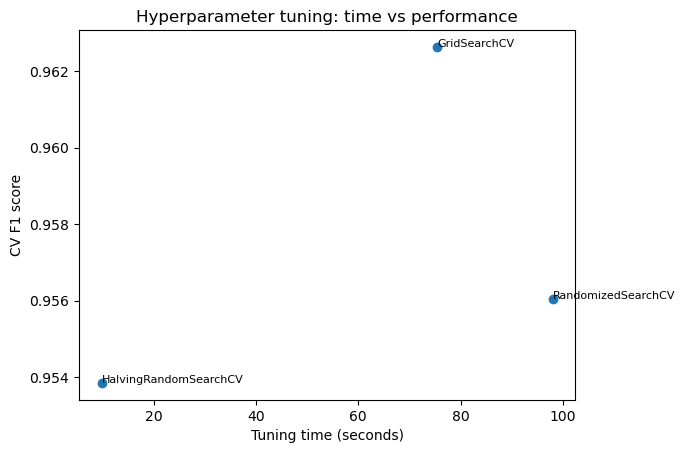

: 

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.scatter(results["time_sec"], results["cv_f1"])
for i, row in results.iterrows():
    plt.text(row["time_sec"], row["cv_f1"], row["method"], fontsize=8)
plt.xlabel("Tuning time (seconds)")
plt.ylabel("CV F1 score")
plt.title("Hyperparameter tuning: time vs performance")
plt.show()